# Which animals actually damage aircraft, and when?
### A linked Plotly + Dash dashboard of 360,000 FAA wildlife strike reports

**Live dashboard** https://wildlife-strikes.onrender.com (free host, so the first load can take up to a minute)
**Code** https://github.com/sjain44/wildlife-strikes-dashboard
**Video** YOUR-VIDEO-LINK

## 1. Introduction

Every year pilots report around 20,000 times their plane hit a bird or some other animal. Most of the time nothing happens. So I got curious about the few strikes that actually do damage, and built a dashboard around four questions.

1. **Is flying getting more dangerous, or are people just reporting more strikes?**
2. **Which animals are rare but cause most of the damage?**
3. **When in the year, and how high up, does each animal get hit?**
4. **Where, and in which part of the flight, does the damage happen?**

You pick a species, a range of years or an airport, and six charts update together to answer them.

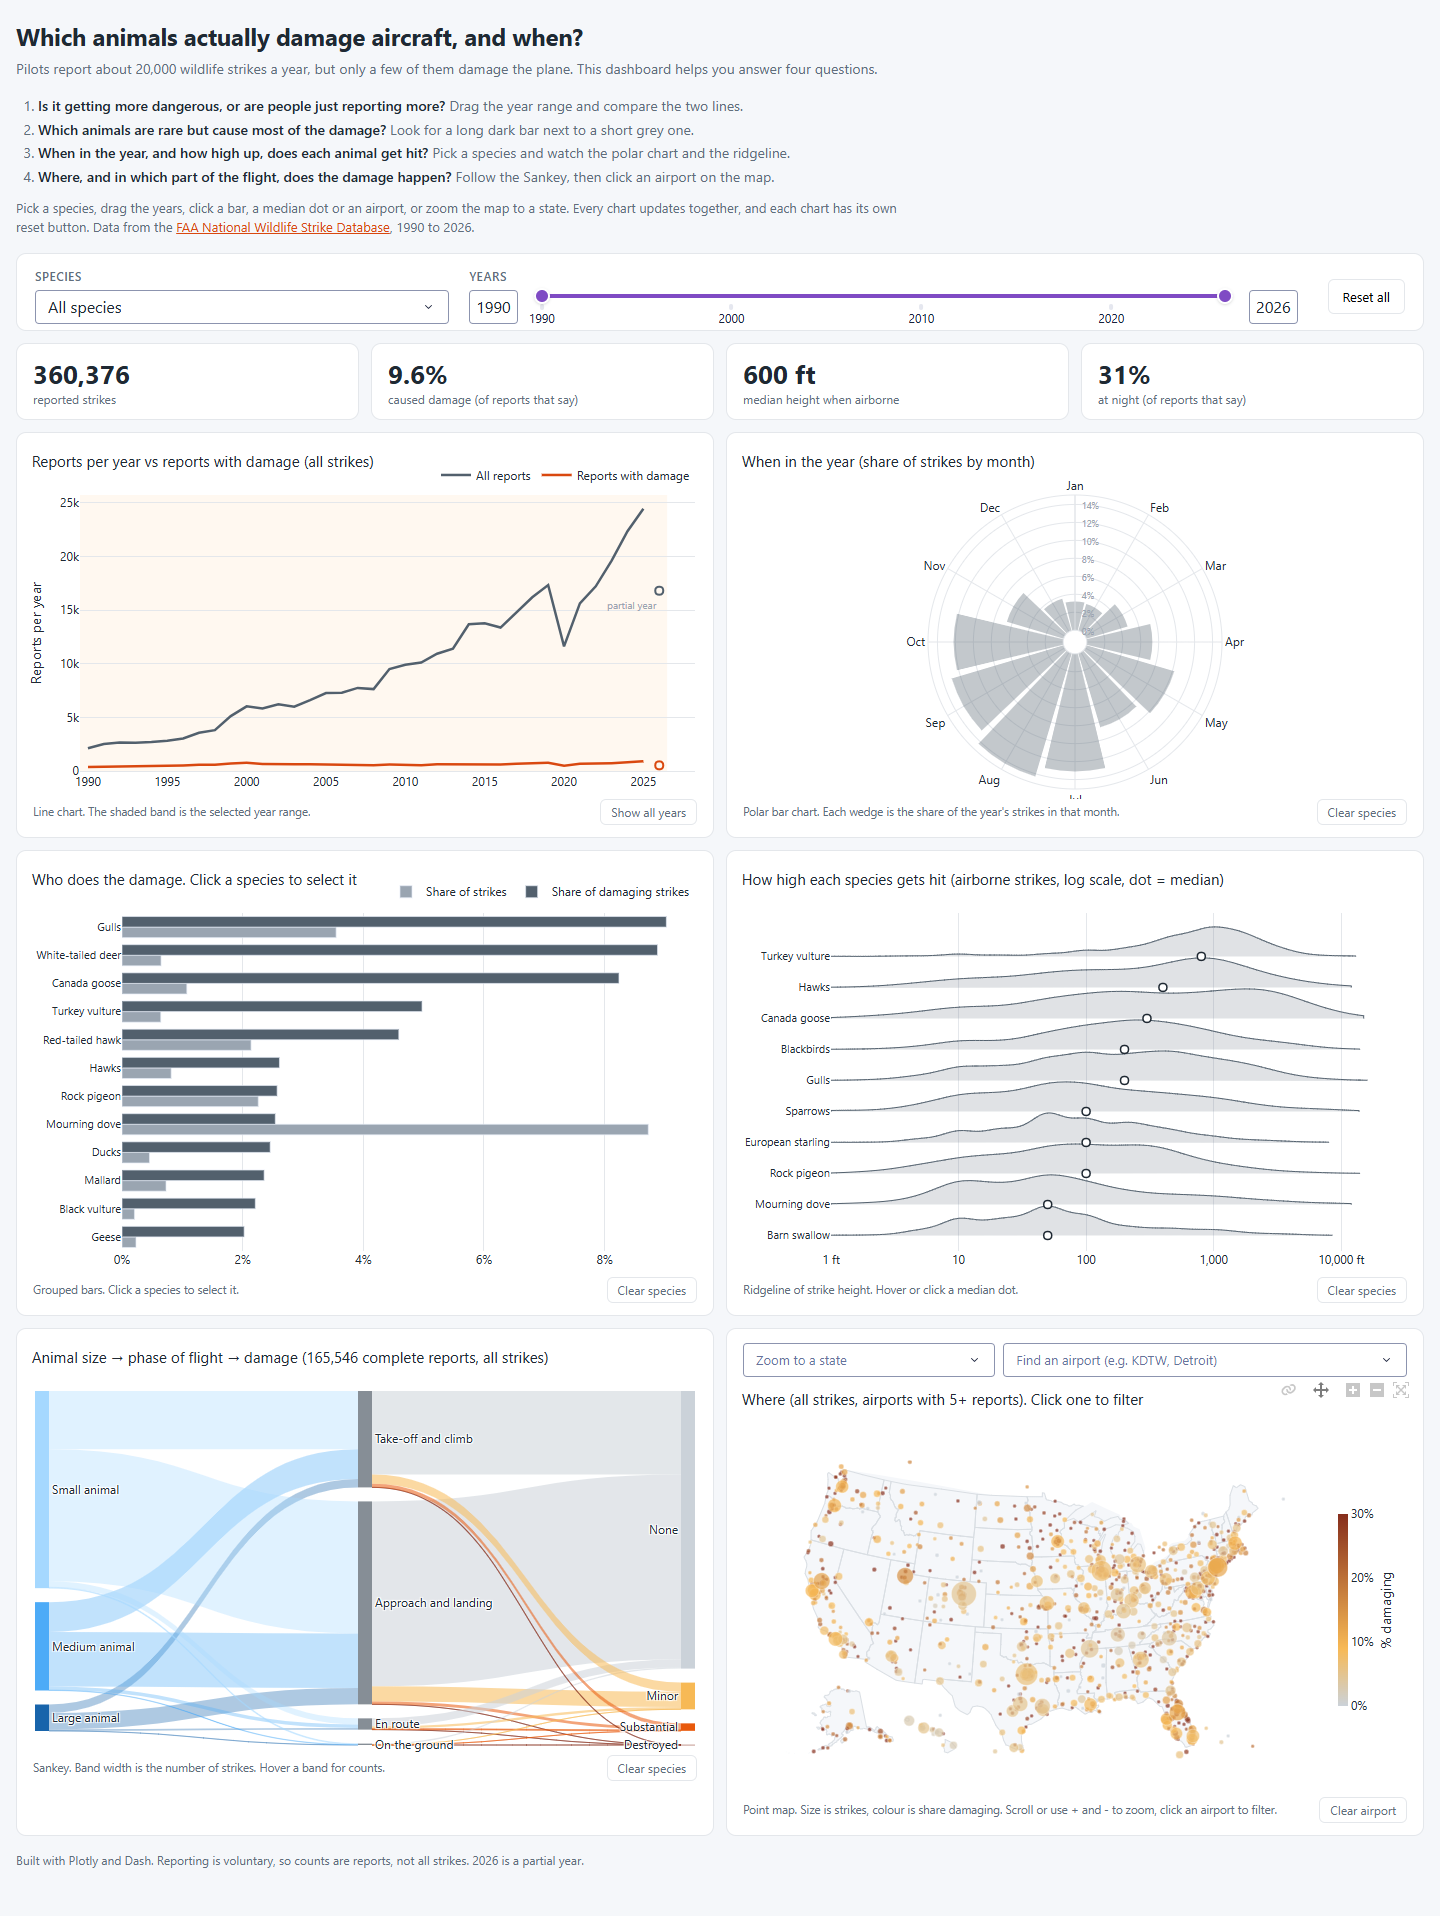

## 2. Library choice and fit

I went with **Plotly** for the charts and **Dash** to tie them together into one app.

| | Plotly (plotly.py, plotly.js) | Dash |
| --- | --- | --- |
| Who made it | Plotly Technologies, started in Montreal in 2012 by Alex Johnson, Jack Parmer, Chris Parmer and Matthew Sundquist | the same company, first released in 2017 with Chris Parmer leading it |
| License | MIT | MIT |
| Install | `pip install plotly` | `pip install dash` (this also installs plotly and Flask) |
| Version I used | plotly 7.1.0 | dash 4.5.0 |

**Declarative, not procedural.** With Plotly I describe what the chart should look like as a big JSON-style object, and plotly.js figures out how to draw it. That felt very different from writing drawing commands line by line. Dash works the same way. I describe the page as a tree of components, and for each callback I just say which inputs it listens to and which outputs it changes. Dash decides when to run it.

**Jupyter.** Plotly charts show up right inside JupyterLab, VS Code and Colab, and you can even run a whole Dash app inside a notebook with `app.run(jupyter_mode="inline")`. In this notebook I save the charts as plain images with `kaleido`, so they still show up when the notebook is turned into HTML or PDF.

**The limitations I ran into**
- Dash needs a Python server running behind it. That means I could not just save the dashboard as one HTML file. It has to be hosted somewhere, and free hosts put the app to sleep when nobody is using it.
- Plotly has no ridgeline chart. I had to fake one by stacking half-violins. Violins do their smoothing in the browser, so this one chart sends about 0.34 MB of raw numbers every time something changes.
- The map draws every point as SVG, which gets very slow with lots of points. Plotting all 300,000 strikes would freeze the page, so I grouped them into 1,186 airports.
- Dash changes quickly. Dash 3 removed `app.run_server`, and Dash 4 replaced the dropdown and the range slider. A lot of the examples I found online simply do not work anymore.

**Why it fits this data.** There are 360,000 rows, which is a lot to push into a browser. With Dash the filtering happens on the server with pandas, which takes about 0.3 seconds, and only six small finished charts get sent to the page. My questions also needed some unusual chart types, like a Sankey for flows, polar bars for a yearly cycle, violins for distributions and a US map that includes Alaska and Hawaii. Plotly has all of these built in. It also reports which bar, ridge or map point you clicked, and that is exactly what I needed to make clicks work as filters.

**What I decided against.** My first idea was Bokeh, since it can save everything as one HTML file and I would not have needed a server. The problem was that all 360,000 rows would have to live inside that file. I would also have had to write the Sankey, the smoothing and the airport totals myself in JavaScript, and Bokeh does not have a Sankey unless you add HoloViews on top. I also thought about Streamlit, but it reruns the whole script every time you touch a control, and its chart selection is built around dragging a box or lasso, not clicking one bar.

## 3. Data

The data comes from the **FAA National Wildlife Strike Database** (https://wildlife.faa.gov/search). The "Download Excel" button gives you a 133 MB zip file with one big spreadsheet inside. I downloaded it on 16 November 2026. It is US government data, so it is in the public domain, and the FAA already hides the names of the people who filed the reports.

The raw file has 360,384 rows and 102 columns, going from 1990 to October 2026. One thing to keep in mind is that reporting is voluntary. Every number in this project is really a count of *reports*, not of every strike that happened.

Here are the columns I ended up using.

| Column (renamed) | What it holds | How complete |
| --- | --- | --- |
| `date`, `year`, `month` | when it happened | 100% |
| `time_of_day` | Day, Night, Dusk, Dawn | 56% |
| `airport_id`, `airport`, `state`, `lat`, `lon` | where it happened | 86% |
| `phase` | part of the flight, 12 values | 60% |
| `height_ft`, `speed_kt` | feet above ground, knots | 49%, 31% |
| `damage_code` | N none, M minor, M? uncertain, S substantial, D destroyed | 65% |
| `species`, `size` | what got hit, and whether it was small, medium or large | 100%, 88% |
| `num_struck`, `operator`, `ac_class` | extra context | 72 to 100% |

### Cleaning steps
Every cell below is copied straight from `prepare_data.py`, so running that one script gives you exactly the same clean file.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
from pathlib import Path
import urllib.request
import zipfile

import numpy as np
import pandas as pd

DATA = Path(__file__).resolve().parent / "data" if "__file__" in globals() else Path("data")
RAW = DATA / "raw"
URL = "https://wildlife.faa.gov/assets/database_excel.zip"

First I download the zip file, but only if I do not already have it, and unzip it.

In [2]:
# Download the zip once. The FAA site's "Download Excel" button points at this file.
RAW.mkdir(parents=True, exist_ok=True)
zip_path = RAW / "database_excel.zip"
if not zip_path.exists():
    urllib.request.urlretrieve(URL, zip_path)
with zipfile.ZipFile(zip_path) as z:
    z.extractall(RAW)

Then I read the spreadsheet. The `calamine` engine reads it in about 35 seconds, which is way faster than the default. I also turn every text column into a clean string, because some columns like `AIRPORT_ID` mix numbers and text and the file would not save otherwise.

In [3]:
# calamine reads the 159 MB workbook in about 35 seconds (openpyxl takes minutes).
raw = pd.read_excel(RAW / "Public.xlsx", engine="calamine")
# Some text columns mix numbers and strings (AIRPORT_ID holds both 123 and "KDTW").
# Cast every object column to a clean, stripped string so parquet can store it.
text_cols = raw.select_dtypes(include=["object", "string"]).columns
raw[text_cols] = raw[text_cols].astype("string").apply(lambda s: s.str.strip())
raw.shape

(360384, 102)

Eight report IDs showed up twice. When I looked closer, the only difference was the species name, either Squirrels or Tree squirrels. So it is a lookup mistake, and I keep the more specific name.

In [4]:
# 8 strike IDs appear twice. The only column that differs is SPECIES ("Squirrels" vs
# "Tree squirrels"), so it is a lookup artifact. Keep the more specific name.
dups = raw[raw["INDEX_NR"].duplicated(keep=False)]
raw = raw[~(raw["INDEX_NR"].duplicated(keep=False) & raw["SPECIES"].eq("Squirrels"))]
assert raw["INDEX_NR"].is_unique
dups[['INDEX_NR', 'INCIDENT_DATE', 'AIRPORT_ID', 'SPECIES']].head(4)

,INDEX_NR,INCIDENT_DATE,AIRPORT_ID,SPECIES
152299,778860,2016-03-01,KPSM,Squirrels
152300,778860,2016-03-01,KPSM,Tree squirrels
162203,793166,2017-04-29,KNUQ,Squirrels
162204,793166,2017-04-29,KNUQ,Tree squirrels


Out of 102 columns I only need 20, so I keep those and give them names that are easier to read.

In [5]:
# Keep the 20 columns the dashboard uses and give them readable names.
cols = {
    "INDEX_NR": "id", "INCIDENT_DATE": "date", "INCIDENT_YEAR": "year",
    "INCIDENT_MONTH": "month", "TIME_OF_DAY": "time_of_day", "AIRPORT_ID": "airport_id",
    "AIRPORT": "airport", "STATE": "state", "LATITUDE": "lat", "LONGITUDE": "lon",
    "OPERATOR": "operator", "AC_CLASS": "ac_class", "PHASE_OF_FLIGHT": "phase",
    "HEIGHT": "height_ft", "SPEED": "speed_kt", "DAMAGE_LEVEL": "damage_code",
    "SPECIES": "species", "SIZE": "size", "NUM_STRUCK": "num_struck",
    "INGESTED_OTHER": "ingested",
}
df = raw[list(cols)].rename(columns=cols)
df.head(3)

,id,date,year,month,time_of_day,airport_id,airport,state,lat,lon,operator,ac_class,phase,height_ft,speed_kt,damage_code,species,size,num_struck,ingested
0,608242,1996-06-22,1996,6,<NA>,KSMF,SACRAMENTO INTL,CA,38.69542,-121.59077,UNITED AIRLINES,A,Take-off Run,0.0,NaN,<NA>,Unknown bird - medium,Medium,1,0
1,608243,1996-06-26,1996,6,<NA>,KDEN,DENVER INTL AIRPORT,CO,39.85841,-104.667,UNITED AIRLINES,A,Take-off Run,0.0,NaN,<NA>,Unknown bird - medium,Medium,1,0
2,608244,1996-07-01,1996,7,<NA>,KOMA,EPPLEY AIRFIELD,NE,41.30252,-95.89417,UNITED AIRLINES,A,Take-off Run,0.0,NaN,N,Unknown bird - medium,Medium,1,0


Dates and coordinates come in as text, so I turn them into real dates and numbers. I also flag the latest year, because the FAA had only checked reports up to about August when I downloaded it.

In [6]:
# Dates and coordinates arrive as text. Convert them, and flag 2026 as a partial year
# because the FAA had only validated reports through about August when I downloaded it.
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["lat"] = pd.to_numeric(df["lat"], errors="coerce")
df["lon"] = pd.to_numeric(df["lon"], errors="coerce")
df["partial_year"] = df["year"].eq(df["year"].max())

Next I turn the damage codes into words. I count a strike as damaging if any damage at all was reported. If the field is blank I call it Not reported, because a blank does not mean nothing happened.

In [7]:
# FAA damage codes: N none, M minor, M? uncertain minor, S substantial, D destroyed.
# A strike counts as damaging if any damage was reported. Blank means not reported.
damage_labels = {"N": "None", "M": "Minor", "M?": "Minor", "S": "Substantial", "D": "Destroyed"}
df["damage"] = df["damage_code"].map(damage_labels).fillna("Not reported")
df["damaging"] = df["damage"].isin(["Minor", "Substantial", "Destroyed"])
df['damage'].value_counts()

damage
None            210533
Not reported    127497
Minor            17825
Substantial       4426
Destroyed           95
Name: count, dtype: int64

There are twelve flight phases, which is too many for one chart, so I group them into four.

In [8]:
# Twelve phase-of-flight values collapse into four groups for the Sankey diagram.
phase_groups = {
    "Parked": "On the ground", "Taxi": "On the ground",
    "Take-off Run": "Take-off and climb", "Climb": "Take-off and climb",
    "Departure": "Take-off and climb",
    "En Route": "En route", "Local": "En route",
    "Descent": "Approach and landing", "Approach": "Approach and landing",
    "Arrival": "Approach and landing", "Landing Roll": "Approach and landing",
}
df["phase_group"] = df["phase"].map(phase_groups).fillna("Not reported")
df['phase_group'].value_counts()

phase_group
Not reported            142818
Approach and landing    136325
Take-off and climb       72191
En route                  8051
On the ground              991
Name: count, dtype: int64

About 40% of reports just say something like Unknown bird. I keep them in the totals but flag them, so they do not show up as a fake species in the species charts.

In [9]:
# 40% of reports name only "Unknown bird - small" and similar. They stay in the totals
# but are excluded from species comparisons, since they are not a real species.
df["unknown_species"] = df["species"].str.contains("unknown", case=False, na=True)
df["size"] = df["size"].fillna("Not reported")
df["time_of_day"] = df["time_of_day"].fillna("Not reported")
round(df['unknown_species'].mean(), 3)

np.float64(0.396)

A height of 0 means the animal was hit on the runway, so the height charts only use strikes that happened in the air.

In [10]:
# HEIGHT is feet above ground. 0 means the animal was hit on the runway, so airborne
# analysis uses height > 0 only. Half the reports leave height blank.
df["airborne"] = df["height_ft"].gt(0)
df['airborne'].sum()

np.int64(100841)

Last, I store the text columns as categories and save a 7 MB parquet file. That small file is the only data the dashboard needs.

In [11]:
for c in ["time_of_day", "state", "ac_class", "phase", "phase_group", "damage",
          "damage_code", "size", "num_struck", "species", "airport", "airport_id", "operator"]:
    df[c] = df[c].astype("category")
DATA.mkdir(exist_ok=True)
df.to_parquet(DATA / "strikes_clean.parquet", index=False)
df.shape

(360376, 26)

I also noticed two quirks while cleaning. The airport code `ZZZZ` means the airport is unknown. That covers 48,847 reports, and since they have no coordinates they just do not appear on the map. The other one surprised me. 86% of the heights are multiples of 50 ft, which means pilots are estimating. So when the height chart shows little bumps at 50, 100 and 500 ft, that is people rounding, not birds.

In [12]:
air = df.loc[df['airborne'], 'height_ft']
pd.Series({'airborne reports': len(air),
           'multiple of 50 ft': round((air % 50 == 0).mean(), 3),
           'unknown airport (ZZZZ)': int(df['airport_id'].eq('ZZZZ').sum())})

airborne reports          100841.000
multiple of 50 ft              0.862
unknown airport (ZZZZ)     48847.000
dtype: float64

## 4. Visualization techniques

Each chart lives in `charts.py` as a function. It takes the filtered data and hands back a finished chart, so this notebook and the live app draw exactly the same thing.

In [13]:
import plotly.io as pio
import charts as C

pio.renderers.default = "png"          # static images so the figures survive HTML/PDF export
pio.renderers["png"].width = 1000

| Chart | What it shows | Why I used it here | When you should not use it |
| --- | --- | --- | --- |
| **Line chart** (covered in class) | reports per year next to damaging reports per year | the reporting trend is the backdrop for every other number | when the x-axis has no natural order, or with lots of lines crossing each other |
| **Polar bar chart** (new to class) | the share of strikes in each month, for the chosen species and for everything | migration goes in a circle, and December really does sit next to January | for anything that is not a cycle, or when exact comparisons matter, since angles and areas are harder to read than bar lengths |
| **Grouped bar chart** (covered in class) | each species' share of strikes next to its share of the damage | it shows right away which animals are rare but costly | with more than about 15 categories, or when the two measures use different units |
| **Ridgeline** (new to class) | the full spread of strike heights for 10 or 11 species, sorted by median | the heights are skewed and lumpy, so I wanted to compare whole shapes instead of one average | when a group has only a few points (the smoothing makes up a shape), or when you need exact numbers |
| **Sankey diagram** (new to class) | strikes flowing from animal size to flight phase to damage | damage depends on two things in a row, and the band widths keep the counts honest | for flows that loop back, or with so many nodes that it turns into spaghetti |
| **Point map** (covered in class) | airports sized by number of reports and coloured by how often there was damage | it answers where, and clicking an airport filters everything else | when people will read circle size as danger (it mostly shows traffic), or when points pile on top of each other |

### What the new chart types show that the usual ones miss
**Ridgeline vs box plot.** Below are the same heights drawn as box plots. The box for Canada goose goes from about 60 to 1,500 ft, which tells me the range but not the shape. The ridgeline right after it shows the real picture. Goose strikes are spread out like a wide plateau, while doves and swallows pile up under 100 ft. The box plot also completely hides those rounding bumps I found during cleaning.

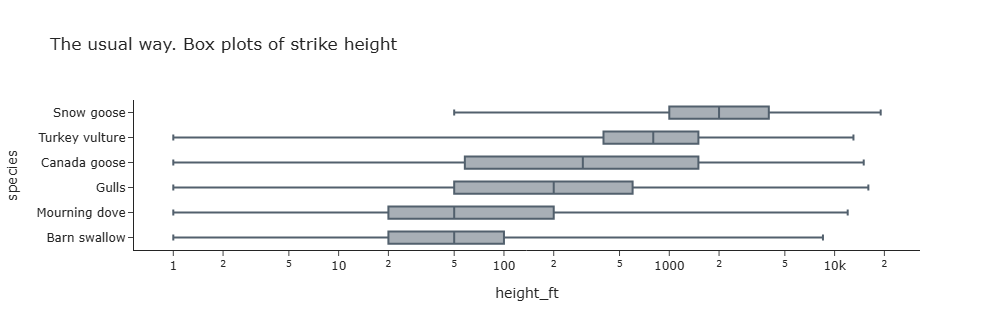

In [14]:
import plotly.express as px
keep = ['Barn swallow', 'Mourning dove', 'Gulls', 'Canada goose', 'Turkey vulture', 'Snow goose']
air = df[df['airborne'] & df['species'].isin(keep)].copy()
air['species'] = air['species'].astype(str)
box = px.box(air, x='height_ft', y='species', log_x=True, points=False,
             category_orders={'species': keep[::-1]}, title='The usual way. Box plots of strike height')
box.update_traces(marker_color=C.BASE).update_layout(height=330, template='simple_white')
box.show()

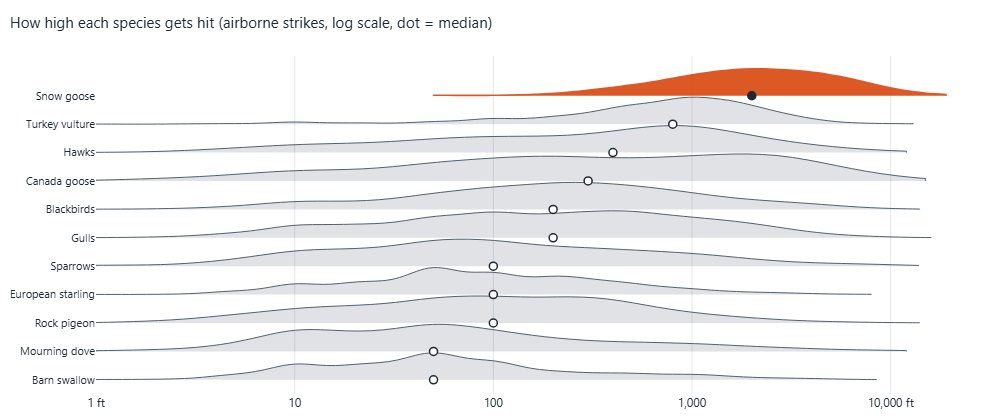

In [15]:
C.height_ridgeline(df, species='Snow goose').show()

**Polar bars vs a line chart.** Snow goose strikes peak from November through January. On a normal January-to-December line, that peak gets cut in half, with one piece at the far left and the other at the far right. On the polar chart it stays in one piece, and you can see it sitting right on top of the summer peak for all other strikes.

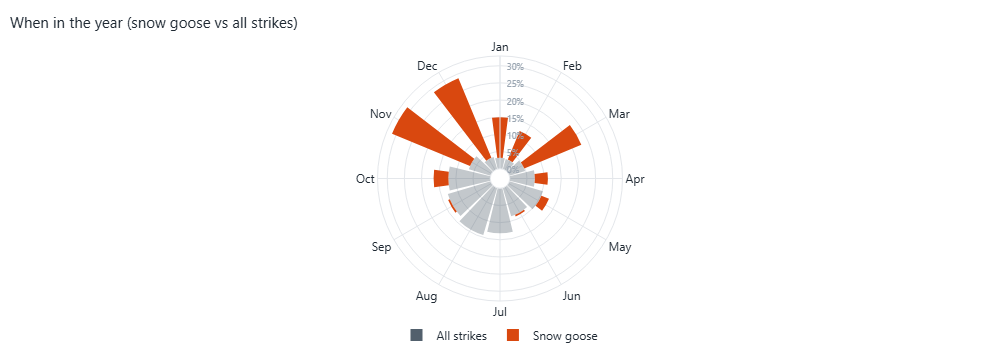

In [16]:
C.seasonal_radial(df, species='Snow goose').show()

**Sankey vs a stacked bar.** A stacked bar can show damage by flight phase or damage by animal size, but not both at once. The Sankey follows each strike through both steps. You can see large animals flowing mostly into approach and landing, and that is where most of the orange damage bands start.

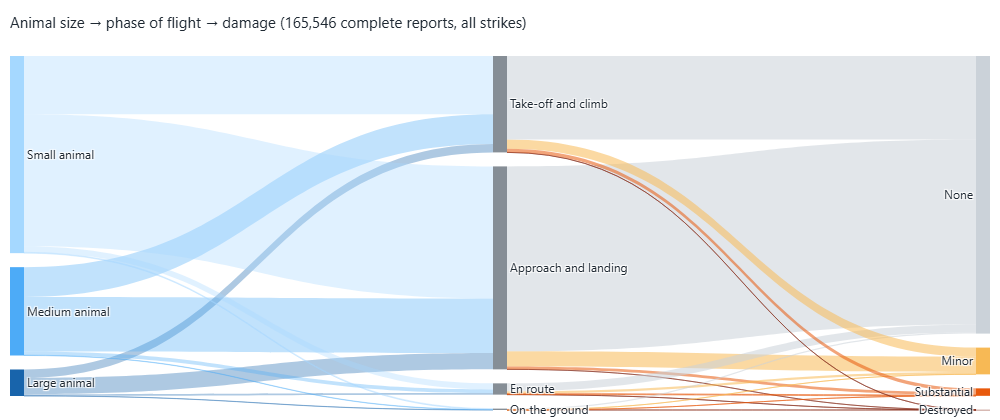

In [17]:
C.damage_sankey(df).show()

### How the charts fit together
I laid the page out so it reads like a story from top to bottom. The top row covers how much and when, with the trend and the season. The middle row is about who, with the bar chart and the ridgeline side by side, since clicking either one picks a species. The bottom row shows how and where, with the Sankey and the map. Orange always means the species you picked, and grey always means everything, so you can follow one choice across all six charts.

## 5. Building and exploring

### Step 1. One chart at a time
I started by building each chart as its own function and testing it on the full data before connecting anything. The ridgeline took the most work, so here is its code.

In [18]:
import inspect
from IPython.display import Markdown
Markdown("```python\n" + inspect.getsource(C.height_ridgeline) + "\n```")

```python
def height_ridgeline(context, species=None, n=10, min_reports=40):
    """Distribution of strike height for the most-reported species (ridgeline).

    Height is on a log scale because it spans 1 ft to 30,000 ft. Each ridge is a
    one-sided violin (a KDE) so the shapes stack without overlapping.
    """
    air = context[context["airborne"] & ~context["unknown_species"].astype(bool)]
    counts = air["species"].value_counts()
    counts = counts[counts >= min_reports]
    chosen = list(counts.index[:n])
    if species not in (None, ALL) and species not in chosen and counts.get(species, 0) >= 5:
        chosen.append(species)
    air = air[air["species"].isin(chosen)]
    order = air.groupby("species", observed=True)["height_ft"].median().sort_values().index.tolist()

    fig = go.Figure()
    medians = []
    for sp in order:
        h = air.loc[air["species"].eq(sp), "height_ft"]
        hit = sp == species
        fig.add_violin(
            x=np.log10(h), y=[sp] * len(h), name=sp, orientation="h", side="positive",
            width=1.9, points=False, spanmode="hard", meanline_visible=False,
            line=dict(color=ACCENT if hit else BASE, width=1.6 if hit else 1),
            fillcolor=ACCENT if hit else "rgba(82,96,109,0.18)", opacity=0.9 if hit else 1,
            hoverinfo="skip",  # the ridge's own hover box floats far outside the plot
        )
        medians.append((sp, h.median(), len(h), hit))
    # one dot per ridge at the median carries a short hover label that stays inside the chart
    m = pd.DataFrame(medians, columns=["species", "median", "n", "hit"])
    fig.add_scatter(
        x=np.log10(m["median"]), y=m["species"], mode="markers",
        marker=dict(size=8, color=np.where(m["hit"], INK, "white"), line=dict(color=INK, width=1.5)),
        customdata=m[["median", "n"]],
        hovertemplate="<b>%{y}</b><br>median %{customdata[0]:,.0f} ft<br>%{customdata[1]:,} airborne strikes<extra></extra>",
    )
    _layout(fig, "How high each species gets hit (airborne strikes, log scale, dot = median)", height=420,
            showlegend=False, hovermode="closest")
    fig.update_xaxes(tickvals=np.log10(TICKS), ticktext=["1 ft", "10", "100", "1,000", "10,000 ft"],
                     gridcolor=GRID, zeroline=False, range=[0, 4.5])
    # leave room above the top ridge so its curve is not clipped
    fig.update_yaxes(categoryorder="array", categoryarray=order, showgrid=False, tickfont=dict(size=11),
                     range=[-0.5, len(order) + 0.4])
    return fig

```

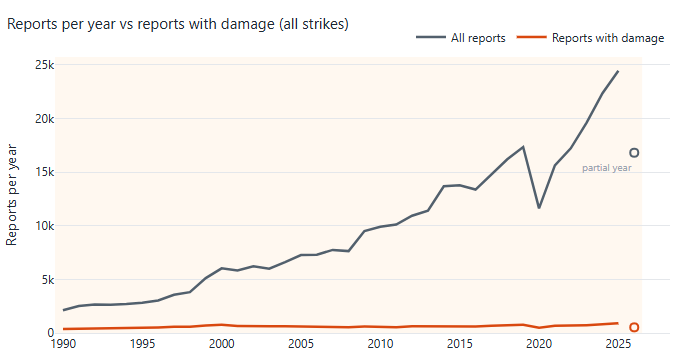 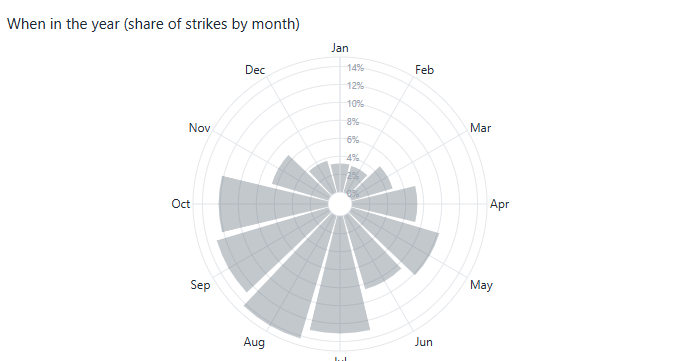
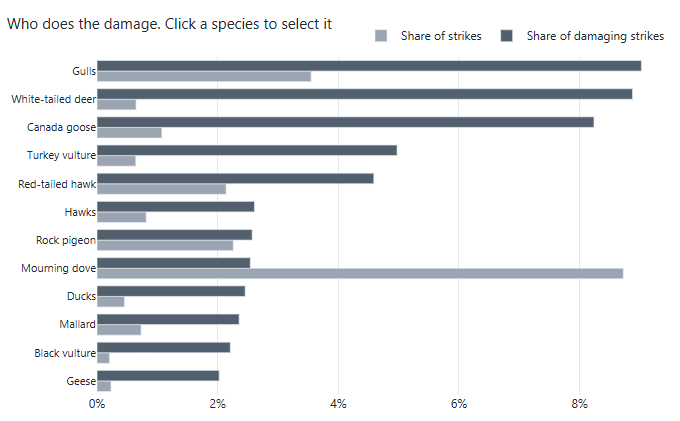 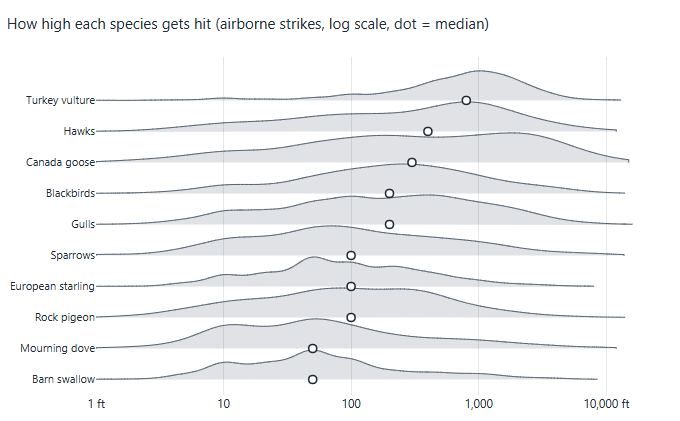

### Step 2. Putting the page together
Next came the layout. There is a control bar that sticks to the top while you scroll, then four headline numbers, then the six charts in a two-column grid. The styling is in `assets/style.css`. On a phone the grid switches to one column. My first try squished every chart down to a few pixels tall, which is entry 2 in the AI log.

```python
app.layout = html.Div(className="page", children=[
    html.Header(...),
    html.Div(className="controls", children=[dcc.Dropdown(id="species", ...),
                                             dcc.RangeSlider(id="years", ...),
                                             html.Button("Reset all", id="reset")]),
    dcc.Store(id="airport"),                       # holds the airport picked on the map
    html.Div(className="kpis", children=[...]),
    html.Div(className="grid", children=[card("trend", note, "years"), card("radial", note, "species"),
                                         card("bar", note, "species"), card("ridge", note, "species"),
                                         card("sankey", note, "species"), card("map", note, "airport")]),
])
```
Each `card` holds a chart, a one-line note and a reset button for the filter that chart controls.

### Step 3. Linking the charts
The linking only takes two callbacks. The first one turns clicks into filter values. The second one takes those values and redraws everything.

| What you do | What updates |
| --- | --- |
| Pick a species in the dropdown | all six charts and all four numbers |
| Click a bar or a ridgeline median dot | picks that species, so everything again |
| Drag the year slider | all six charts (the trend chart shades the years you picked) |
| Click an airport on the map, or type one into Find an airport | filters the other five charts to that airport and zooms the map to its state |
| Zoom to a state (above the map) | zooms the map so single airports are easy to pick |
| A chart's own reset button | clears just that chart's filter (Show all years, Clear species, Clear airport) |
| Hit Reset all | clears everything |

Each chart also shows a small toolbar on hover with a button to reset its zoom. The map keeps its + and - zoom buttons visible all the time and also zooms with the scroll wheel. Once it is zoomed in, it switches from the national map projection to a regular one and shows lakes and state borders, so you can find something like Detroit Metro in Wayne County, Michigan.

Each chart ignores the one filter that would make it useless. The trend chart always shows every year so the shaded band has something to compare to. The map always shows every airport so you can click a different one. The bar chart and ridgeline always show every species, because that is where you pick one.

In [19]:
import app as A
Markdown("```python\n" + inspect.getsource(A.handle_clicks) + "\n" + inspect.getsource(A.update) + "\n```")

```python
@app.callback(
    Output("species", "value"), Output("years", "value"), Output("airport", "data"),
    Output("airport-pick", "value"), Output("map-state", "value"),
    Input("bar", "clickData"), Input("ridge", "clickData"), Input("map", "clickData"),
    Input("airport-pick", "value"),
    Input("reset", "n_clicks"), Input({"type": "card-reset", "chart": ALL, "target": ALL}, "n_clicks"),
    State("species", "value"), State("airport", "data"),
    prevent_initial_call=True,
)
def handle_clicks(bar_click, ridge_click, map_click, picked, _reset, _card_resets, species, airport):
    """Clicks on one chart become filters for all the others. Reset buttons clear them."""
    trigger = ctx.triggered_id
    skip = (no_update,) * 5
    if trigger == "reset":
        return C.ALL, [YEAR_MIN, YEAR_MAX], None, None, None
    if isinstance(trigger, dict) and trigger.get("type") == "card-reset":
        if not ctx.triggered[0]["value"]:      # ignore the buttons being created
            return skip
        target = trigger["target"]
        if target == "airport":                # also zoom the map back out
            return no_update, no_update, None, None, None
        return (C.ALL if target == "species" else no_update,
                [YEAR_MIN, YEAR_MAX] if target == "years" else no_update, no_update, no_update, no_update)
    if trigger == "bar" and bar_click:
        sp = bar_click["points"][0]["y"]
        return (C.ALL if sp == species else sp), no_update, no_update, no_update, no_update
    if trigger == "ridge" and ridge_click:
        sp = ridge_click["points"][0].get("y")
        if sp in SPECIES_SET:
            return (C.ALL if sp == species else sp), no_update, no_update, no_update, no_update
    if trigger == "map" and map_click:
        code = map_click["points"][0]["customdata"][0]
        code = None if code == airport else code
        return no_update, no_update, code, code, no_update
    if trigger == "airport-pick":
        return no_update, no_update, picked, no_update, no_update
    return skip

@app.callback(
    Output("trend", "figure"), Output("radial", "figure"), Output("bar", "figure"),
    Output("ridge", "figure"), Output("sankey", "figure"), Output("map", "figure"),
    Output("k-strikes", "children"), Output("k-damaging", "children"),
    Output("k-height", "children"), Output("k-night", "children"), Output("airport-chip", "children"),
    Input("species", "value"), Input("years", "value"), Input("airport", "data"),
    Input("map-state", "value"),
)
def update(species, years, airport, map_state=None):
    """One control change redraws all six charts and the four headline numbers."""
    selected = C.filter_strikes(DF, species, years, airport)          # all three filters
    context = C.filter_strikes(DF, None, years, airport)              # every species, for comparison
    over_time = C.filter_strikes(DF, species, None, airport)          # every year, for the trend line
    on_map = C.filter_strikes(DF, species, years, None)               # every airport, so the map stays clickable
    k = C.kpis(selected)
    chip = "" if not airport else f"Airport {airport} (click it again to clear)"
    # zoom to the chosen state, or else to the state of the chosen airport
    zoom_state = map_state or AIRPORT_STATE.get(airport)
    bounds = STATE_BOUNDS.get(zoom_state)
    place = STATE_NAMES.get(zoom_state) if bounds else None
    return (
        C.trend_chart(over_time, years, species),
        C.seasonal_radial(context, species),
        C.species_damage_bar(context, species),
        C.height_ridgeline(context, species),
        C.damage_sankey(selected, species),
        C.airport_map(on_map, airport, species, bounds=bounds, place=place),
        k["strikes"], k["damaging"], k["height"], k["night"], chip,
    )

```

To make sure the links actually worked, I wrote a Playwright script (`scripts/shoot.py`). It opens the running app in Edge, clicks through every control, prints the four headline numbers after each step and saves the screenshots you see in this notebook. Every control changed the numbers, and reset put them back.

```
initial            ['360,376', '9.6%',  '600 ft',   '31%']
snow goose         ['211',     '77.0%', '2,000 ft', '73%']  Snow goose (211)
after bar click    ['7,728',   '18.6%', '200 ft',   '14%']  Gulls (7,728)
after map click    ['92',      '19.1%', '500 ft',   '20%']  Airport KDEN*
after ridge click  ['1,399',   '56.8%', '800 ft',   '2%']   Turkey vulture (1,399)
years 2015+        ['203,212', '6.8%',  '800 ft',   '32%']
after reset        ['360,376', '9.6%',  '600 ft',   '31%']
phone scroll width 390, console errors []
```

### What I found

**The questions I started with.** Do strikes peak during migration, and is it the same peak for every animal? Which animals are rare but do a lot of the damage? Are strikes higher up worse? And if reports keep going up, does that mean flying is getting more dangerous?

**The rising line is mostly more reporting.** When I dragged the year slider from the 1990s to the 2020s, the number of reports went up about six times, from around 3,100 a year to 18,500 a year. Damaging strikes only went up about one and a half times, from 486 to 719 a year. The share of strikes that caused damage dropped from 19.2% to 6.5%. So airports are just reporting a lot more of the small stuff, and the rising line does not mean flying got more dangerous.

In [20]:
decades = {'1990-99': (1990, 1999), '2000-09': (2000, 2009), '2010-19': (2010, 2019), '2020-25': (2020, 2025)}
rows = {}
for name, (a, b) in decades.items():
    s = df[df['year'].between(a, b)]
    known = s['damage'].ne('Not reported')
    rows[name] = {'reports per year': round(len(s) / (b - a + 1)),
                  'damaging per year': round(s['damaging'].sum() / (b - a + 1)),
                  'damaging share of known': f"{s['damaging'].sum() / known.sum():.1%}",
                  'damage field filled': f"{known.mean():.0%}"}
pd.DataFrame(rows).T

,reports per year,damaging per year,damaging share of known,damage field filled
1990-99,3096,486,19.2%,82%
2000-09,7015,626,12.2%,73%
2010-19,13150,638,8.0%,61%
2020-25,18490,719,6.5%,60%


**Things that did not work out.** At first I wanted to use repair cost to measure harm, but it turns out only 1.5% of reports even fill it in, so I used the damage level instead (65% filled in). I also expected the map to point out dangerous airports. It did not. The big circles mostly show which airports file lots of reports, and the busy ones actually have lower damage rates (a Spearman correlation of minus 0.34 across airports with at least 100 reports). On top of that, 40% of reports do not name the species and half do not give a height, so each chart title says exactly what it includes.

**The finding I only got by clicking around.** Looking at all species together, the season peaks from July to September, the typical strike happens at 600 ft, 31% happen at night and 9.6% cause damage. Then I picked **Snow goose** in the dropdown and every chart changed at once.

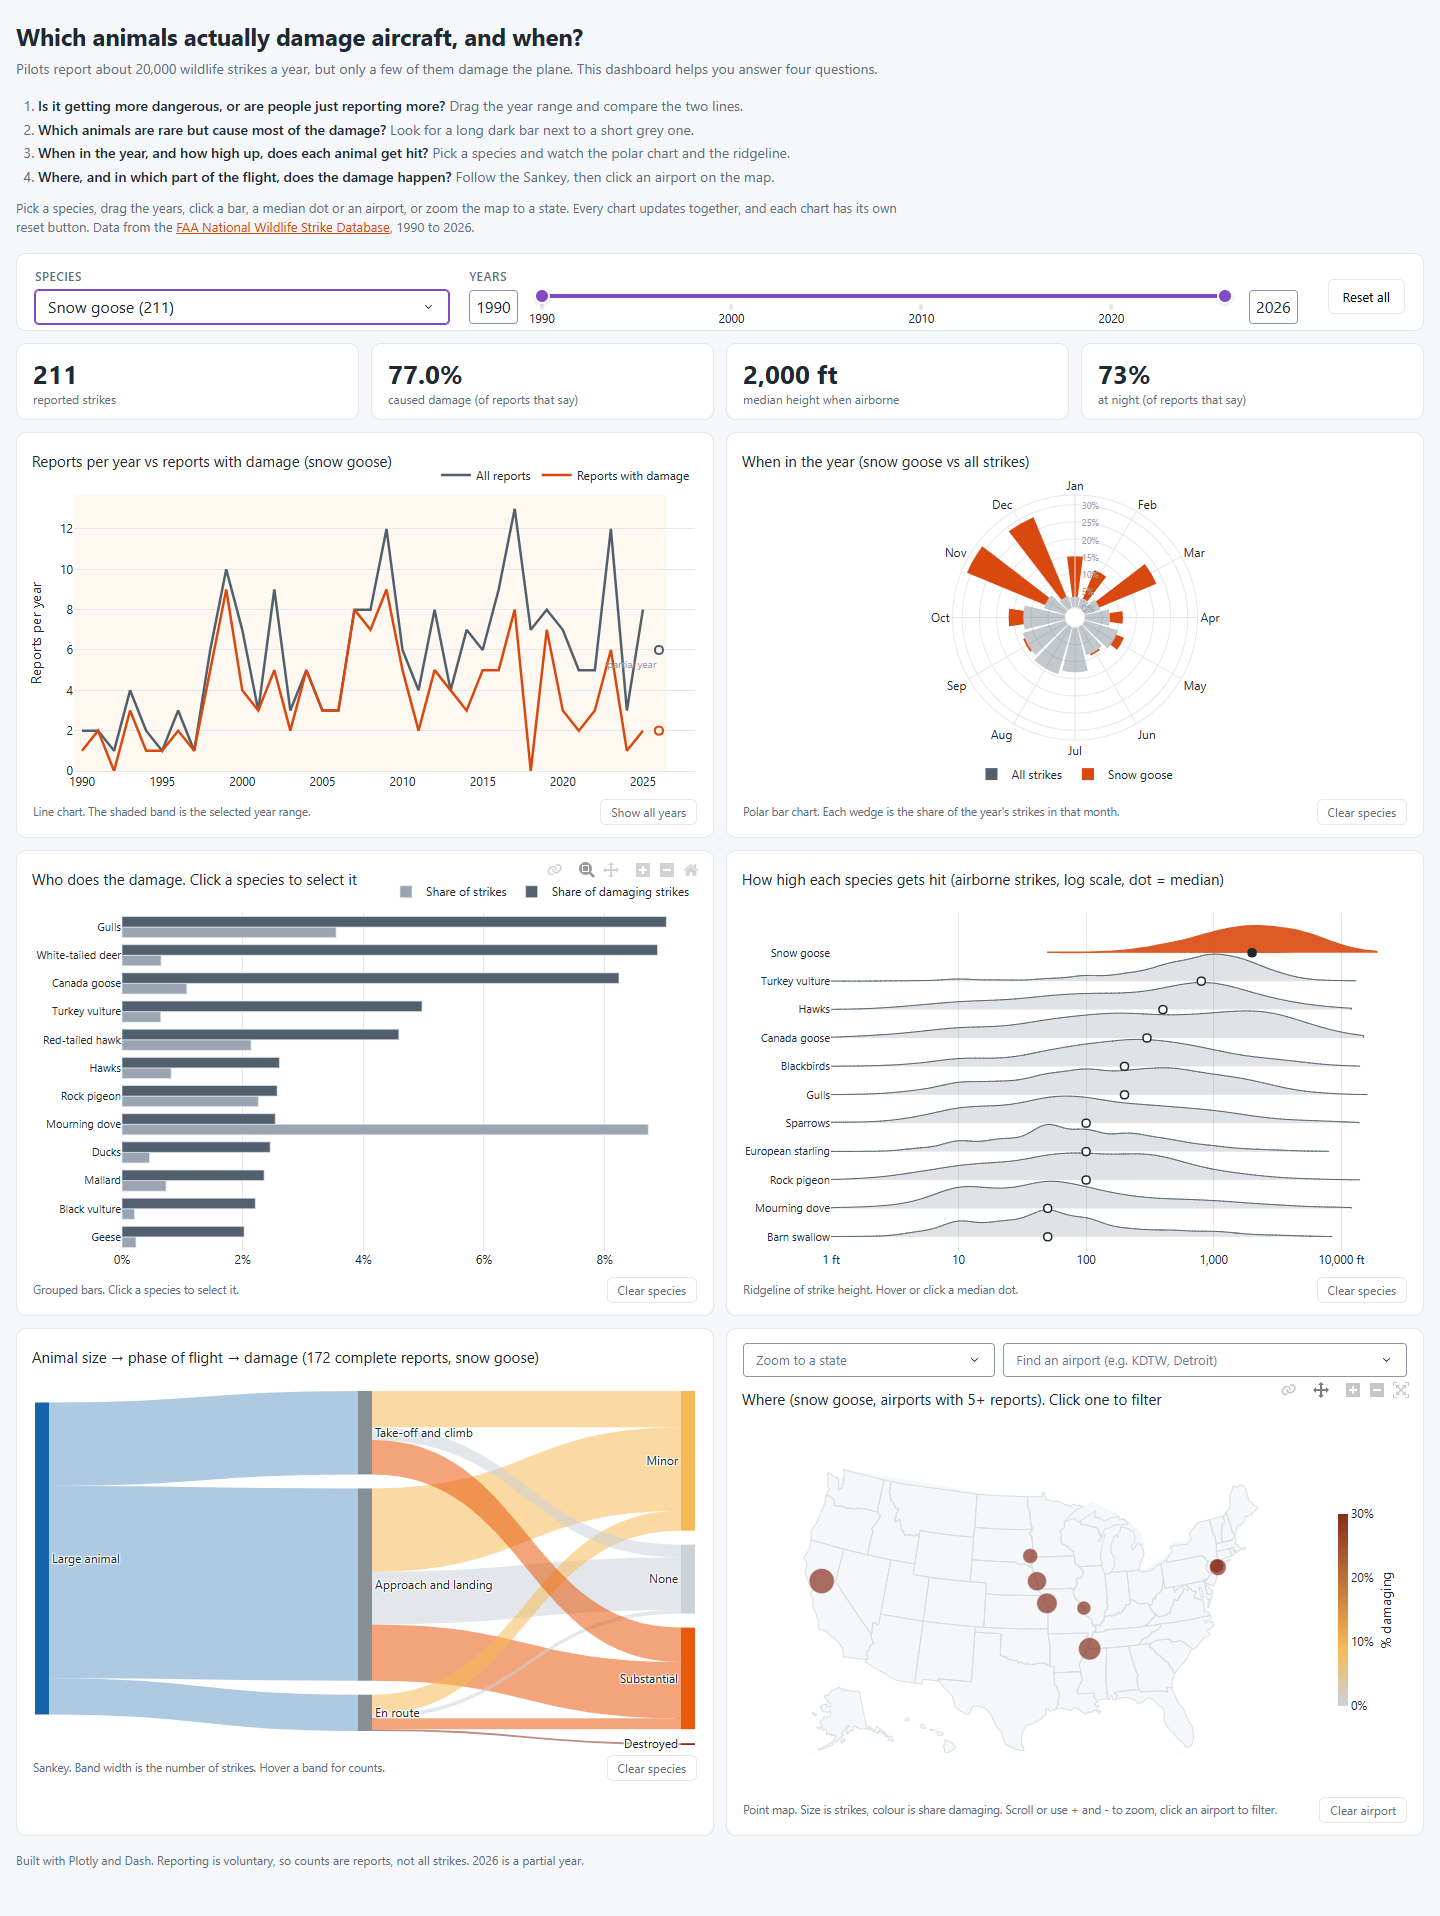

In [21]:
def profile(sub):
    known = sub['damage'].ne('Not reported'); tod = sub['time_of_day'].ne('Not reported')
    months = sub['month'].value_counts(normalize=True)
    return {'reports': len(sub),
            'damaging share': f"{sub['damaging'].sum() / known.sum():.1%}",
            'median airborne height (ft)': sub.loc[sub['airborne'], 'height_ft'].median(),
            'at night': f"{sub['time_of_day'].eq('Night').sum() / tod.sum():.0%}",
            'Nov-Jan share': f"{months.reindex([11, 12, 1]).sum():.0%}",
            'Jul-Aug share': f"{months.reindex([7, 8]).fillna(0).sum():.0%}"}

pd.DataFrame({'All strikes': profile(df),
              'Snow goose': profile(df[df['species'].eq('Snow goose')]),
              'White-tailed deer': profile(df[df['species'].eq('White-tailed deer')]),
              'Brazilian free-tailed bat': profile(df[df['species'].eq('Brazilian free-tailed bat')])})

,All strikes,Snow goose,White-tailed deer,Brazilian free-tailed bat
reports,360376,211,1410,2030
damaging share,9.6%,77.0%,86.4%,1.0%
median airborne height (ft),600.0,2000.0,4.0,400.0
at night,31%,73%,63%,84%
Nov-Jan share,14%,62%,27%,7%
Jul-Aug share,27%,0%,20%,35%


Snow geese are only 0.06% of all reports, so they basically disappear in any chart of everything. Once I selected them, the polar chart flipped to winter, with 62% of their strikes from November to January and none at all in July or August. Their ridge jumped to the very top at a typical height of 2,000 ft. 73% of their strikes happen at night, and 77% cause damage. The map lit up California, Missouri, Tennessee and Nebraska, which sit right under big waterfowl migration routes. I never would have drawn a snow goose chart on purpose, because there are almost a thousand species in this data. The only reason I found it is that I could click around.

Comparing a few more animals showed me what is really going on. Deer cause damage 86% of the time, at a typical height of 4 ft, mostly at night while the plane is landing. Free-tailed bats get hit at night even more often (84%), but they cause damage only 1% of the time. So night and height are not dangerous on their own. Size is what matters, and the Sankey shows big animals feeding straight into the damage bands.

The map had one more surprise. Clicking Denver showed a second airport, `KDEN*`, sitting right on top of it. It is the old Stapleton airport. 91 of its 92 reports are from 1990 to 1994, and their 19% damage rate matches the early-years pattern from the trend chart. The last report is dated 2025, which has to be a typo, since Stapleton closed in 1995.

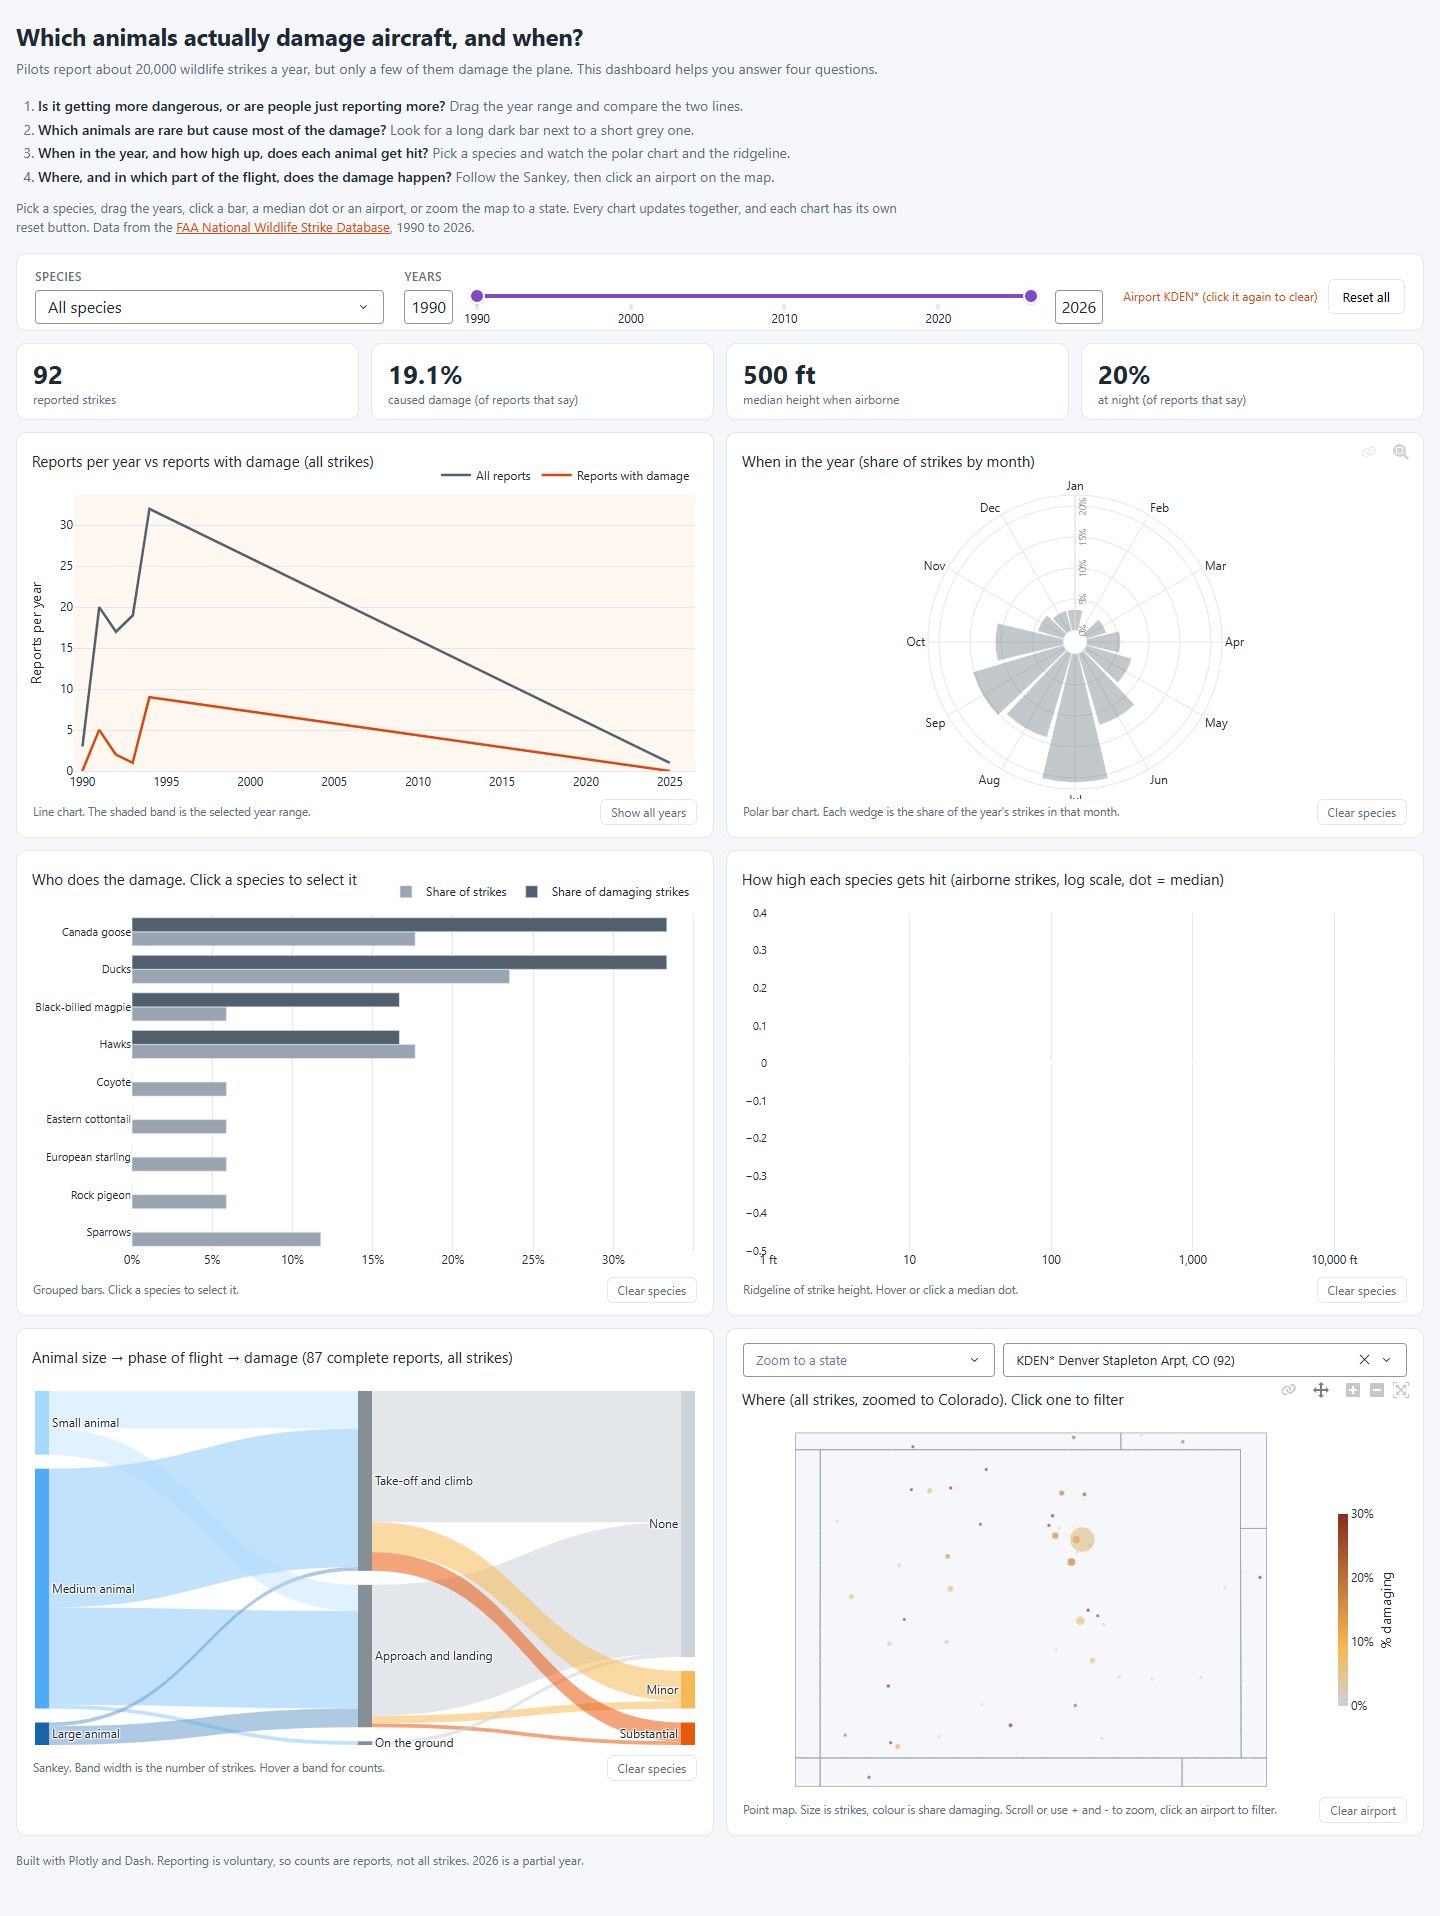

## 6. AI log and troubleshooting

I used Claude (in Claude Code) throughout and checked its work against the data, the live app and the library. Entries 3 and 4 are the problems.

**Entry 1. Evaluating data sources**
- Tool: Claude
- What I asked for / what I was trying to do: compare public datasets that could support four chart types, linked filters and a non-obvious finding.
- What came back / what happened: a shortlist (FAA wildlife strikes, Nobel laureates, Ember electricity data) with licenses, column richness and question ideas.
- What was wrong or could be better: it was not sure the FAA file was still downloadable, and one question it suggested (repair cost by species) only works for 1.5% of reports.
- How I noticed: I found the real "Download Excel" link on the FAA site and profiled how complete every column was.
- What I did instead: picked the FAA data and measured harm with damage level (65% complete) instead of cost.

**Entry 2. Hosting**
- Tool: Claude
- What I asked for / what I was trying to do: host the dashboard from my GitHub repo.
- What came back / what happened: it pointed out that GitHub Pages cannot run a Python server and set up Render with `render.yaml` instead.
- What was wrong or could be better: nothing broke, but the free plan has 512 MB of memory and two app workers would not fit.
- How I noticed: I measured the app at about 250 MB per process.
- What I did instead: run one worker with four threads.

**Entry 3. Chart rendering and wrong text**
- Tool: Claude
- What I asked for / what I was trying to do: build and title the six charts.
- What came back / what happened: three specific errors. A `responsive=True` setting squished every chart to a few pixels tall. The trend title said damaging strikes "do not" rise. And the ridgeline hover box was hard to read and spilled outside the chart.
- What was wrong or could be better: the layout broke, the title was false (damaging strikes rose from about 486 to 719 a year, just slower than reports), and the hover was unusable.
- How I noticed: the first screenshot, my decade table, and using the live app myself.
- What I did instead: removed the setting, used a neutral title with the real numbers in the text, and moved the hover to one dot per ridge at the median with a short white label.

**Entry 4. No way to reset filters**
- Tool: Claude
- What I asked for / what I was trying to do: let people undo a filter on any chart.
- What came back / what happened: the first version only had one Reset all button, hid Plotly's toolbar, and showed the whole country on the map with no way to zoom.
- What was wrong or could be better: you could not clear just one chart's filter, and picking one airport (like Detroit Metro in Wayne County) out of a crowded national map was nearly impossible.
- How I noticed: clicking around the live dashboard.
- What I did instead: added a reset button under every chart (Show all years, Clear species, Clear airport), brought the toolbar back, and added scroll zoom, a Zoom to a state dropdown and a searchable Find an airport box to the map. The Playwright script tests every one of them.

## 7. Deployment

The code lives on GitHub at https://github.com/sjain44/wildlife-strikes-dashboard, and the app runs for free on **Render**, which builds it straight from that repo. A Python server cannot run on GitHub Pages, so I needed a host that actually runs Python. On the free plan the app goes to sleep after about 15 minutes with no visitors, so the first visit can take up to a minute to wake up.

Here is how to do it yourself.
1. Put the project on GitHub. The repo needs `app.py`, `charts.py`, `assets/`, `data/strikes_clean.parquet`, `requirements.txt` and `render.yaml`.
2. Sign up at render.com with your GitHub account, then click **New** and choose **Blueprint**.
3. Pick your repo. Render reads `render.yaml`, which tells it to install `requirements.txt` with Python 3.12 and start the app with `gunicorn app:server`. That is why `app.py` has the line `server = app.server`.
4. Click **Apply** and wait a few minutes for the first build. The app then shows up at a link like `https://wildlife-strikes.onrender.com`.
5. Open the link in a private window and click a bar, a ridgeline dot, an airport, the map zoom and a reset button to make sure everything works without installing anything.

I run only one worker with four threads, because each Python process uses about 250 MB and the free plan has 512 MB. Every time I push to GitHub, Render rebuilds the app automatically.

To run it on your own computer instead, use `pip install -r requirements.txt` and then `python app.py`, and open http://127.0.0.1:8050. To rebuild the data from scratch, install `requirements-notebook.txt` and run `python prepare_data.py`.